# Seamount detection vs a published catalog

In [1]:
import urllib.request
import numpy as np
import matplotlib.pyplot as plt
from scipy import ndimage
from scipy.optimize import linear_sum_assignment
import seafloor as sf

lon, lat, z_raw = sf.load()
z = np.load(sf.DATA_DIR / "z_clean.npy")
_, _, zm = sf.load(layer="topo-mask"); ship = ~np.isnan(zm)
dx, dy = sf.cell_size_m(lon, lat); DX = float(dx.mean())
extent = [lon[0], lon[-1], lat[0], lat[-1]]; aspect = 1 / np.cos(np.deg2rad(lat.mean()))
AREA_KM2 = (lon[-1] - lon[0]) * 111.32 * np.cos(np.deg2rad(lat.mean())) * (lat[-1] - lat[0]) * 110.57
shade = sf.hillshade(z_raw, dx, dy)
print(f"Grid {z.shape}, cell ≈ {DX:.0f} m, region ≈ {AREA_KM2:,.0f} km²")

Grid (1365, 1824), cell ≈ 478 m, region ≈ 578,147 km²


In [2]:
import zipfile, re
ZIP = sf.DATA_DIR / "SIO_Seamounts.zip"
OUT = sf.DATA_DIR / "SIO_Seamounts"
URL = "https://zenodo.org/records/7718512/files/SIO_Seamounts.zip?download=1"
if not OUT.exists():
    if not ZIP.exists():
        print("Downloading", URL)
        req = urllib.request.Request(URL, headers={"User-Agent": "unseen-seafloor"})
        ZIP.write_bytes(urllib.request.urlopen(req, timeout=300).read())
    zipfile.ZipFile(ZIP).extractall(OUT)
files = sorted(p for p in OUT.rglob("*") if p.is_file())
for p in files: print(f"  {p.relative_to(OUT)}  ({p.stat().st_size/1e3:,.0f} kB)")

  SIO_Seamounts/Methods/KWSMTSv01.kml  (18,536 kB)
  SIO_Seamounts/Methods/README.txt  (1 kB)
  SIO_Seamounts/Seamounts_Modeled/KW_badlist.txt  (5 kB)
  SIO_Seamounts/Seamounts_Modeled/README.txt  (2 kB)
  SIO_Seamounts/Seamounts_Modeled/all.xyhrdnc  (2,772 kB)
  SIO_Seamounts/Seamounts_Modeled/good.xyhrdnc  (2,485 kB)
  SIO_Seamounts/Seamounts_Modeled/shallow.xyhrdnc  (108 kB)
  SIO_Seamounts/Seamounts_Modeled/short.xyhrdnc  (29 kB)
  SIO_Seamounts/Seamounts_Modeled/tall.xyhrdnc  (149 kB)


In [3]:
def read_catalog(path):
    rows = []
    for line in path.read_text(errors="ignore").splitlines():
        p = line.split()
        if len(p) < 7: continue
        try: rows.append([float(p[0]), float(p[1]), float(p[2]), float(p[3]), float(p[4]), float(p[6])])
        except ValueError: continue
    return np.array(rows)

def read_kml_points(path):
    pts = re.findall(r"<coordinates>\s*([-\d.]+),([-\d.]+)", path.read_text(errors="ignore"))
    return np.array(pts, float).reshape(-1, 2)

def in_region(lo, la):
    lo = lo % 360
    return (lo > lon[0]) & (lo < lon[-1]) & (la > lat[0]) & (la < lat[-1])

good = [p for p in files if p.name == "good.xyhrdnc"][0]
allcat = read_catalog(good)
print(f"Gevorgian 2023 'good' catalog: {len(allcat):,} seamounts worldwide")
cat = allcat[in_region(allcat[:, 0], allcat[:, 1])]
c_lon, c_lat, c_h, c_charted = cat[:, 0] % 360, cat[:, 1], cat[:, 2], cat[:, 5] == 1
print(f"In our region: {len(cat)}   charted: {c_charted.sum()}, uncharted: {(~c_charted).sum()}")
print(f"Heights here: {c_h.min():,.0f}–{c_h.max():,.0f} m (median {np.median(c_h):,.0f})")

kml = [p for p in files if p.suffix.lower() == ".kml" and not p.name.startswith("._")]
kw = np.vstack([read_kml_points(p) for p in kml]) if kml else np.empty((0, 2))
kw = kw[in_region(kw[:, 0], kw[:, 1])]
print(f"Kim & Wessel 2011 picks in our region: {len(kw)}")

ci = np.clip(np.searchsorted(lat, c_lat), 0, len(lat) - 1); cj = np.clip(np.searchsorted(lon, c_lon), 0, len(lon) - 1)
c_ship = ship[ci, cj]
print(f"Catalog seamounts in our ship-measured area: {c_ship.sum()}, satellite-only: {(~c_ship).sum()}")
print(f"Agreement between their 'charted' flag and our ship mask: {(c_charted == c_ship).mean():.0%}")

Gevorgian 2023 'good' catalog: 39,399 seamounts worldwide
In our region: 118   charted: 108, uncharted: 10
Heights here: 700–2,500 m (median 1,600)


Kim & Wessel 2011 picks in our region: 88
Catalog seamounts in our ship-measured area: 78, satellite-only: 40
Agreement between their 'charted' flag and our ship mask: 75%


In [4]:
def detect(z, sigma_m=1500, r_local_m=3000, r_base_m=15000):
    zf = np.where(np.isnan(z), np.nanmedian(z), z)
    zs = ndimage.gaussian_filter(zf, sigma_m / DX)
    r = int(r_local_m / DX)
    disk = np.hypot(*np.mgrid[-r:r+1, -r:r+1]) <= r
    is_max = ndimage.maximum_filter(zs, footprint=disk) == zs
    k = 4
    base = ndimage.percentile_filter(zs[::k, ::k], 10, size=int(2 * r_base_m / (DX * k)) + 1)
    base = ndimage.zoom(base, (zs.shape[0] / base.shape[0], zs.shape[1] / base.shape[1]), order=1)
    base = base[:zs.shape[0], :zs.shape[1]]
    height = zs - base
    edge = int(r_base_m / DX / 3)
    valid = ~np.isnan(z); valid[:edge] = valid[-edge:] = False; valid[:, :edge] = valid[:, -edge:] = False
    ii, jj = np.nonzero(is_max & valid & (height > 100))
    return dict(lat=lat[ii], lon=lon[jj], h=height[ii, jj], depth=zs[ii, jj], ship=ship[ii, jj])

det_all = detect(z)
print(f"Candidate peaks (height > 100 m): {len(det_all['h']):,}")

Candidate peaks (height > 100 m): 854


Best F1 = 0.49 at h_min = 1100 m


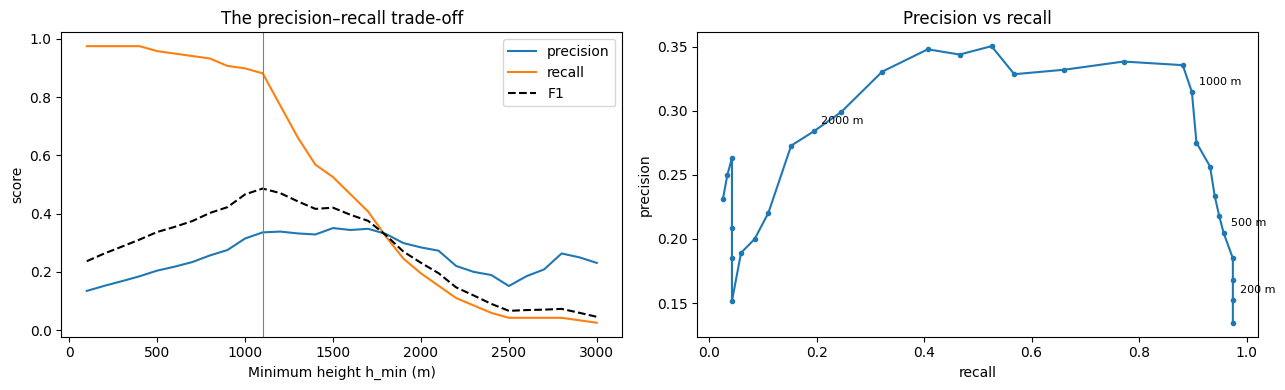

In [5]:
def match(d_lat, d_lon, c_lat, c_lon, max_km=10):
    if len(d_lat) == 0 or len(c_lat) == 0:
        return np.zeros(len(d_lat), bool), np.zeros(len(c_lat), bool), np.array([])
    D = sf.distance_km(d_lat[:, None], d_lon[:, None], c_lat[None, :], c_lon[None, :])
    cost = np.where(D <= max_km, D, 1e6)
    r, c = linear_sum_assignment(cost)
    ok = cost[r, c] <= max_km
    dm = np.zeros(len(d_lat), bool); cm = np.zeros(len(c_lat), bool)
    dm[r[ok]] = True; cm[c[ok]] = True
    return dm, cm, np.c_[r[ok], c[ok]]

def score(h_min, subset=None):
    keep = det_all["h"] >= h_min
    if subset is not None: keep &= subset
    d = {k: v[keep] for k, v in det_all.items()}
    dm, cm, pairs = match(d["lat"], d["lon"], c_lat, c_lon)
    P = dm.mean() if len(dm) else np.nan; R = cm.mean() if len(cm) else np.nan
    return d, dm, cm, pairs, P, R

H = np.arange(100, 3001, 100)
PR = np.array([score(h)[4:] for h in H])
F1 = 2 * PR[:, 0] * PR[:, 1] / (PR[:, 0] + PR[:, 1])
best = H[np.nanargmax(F1)]
print(f"Best F1 = {np.nanmax(F1):.2f} at h_min = {best} m")

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(H, PR[:, 0], label="precision"); axes[0].plot(H, PR[:, 1], label="recall"); axes[0].plot(H, F1, "k--", label="F1")
axes[0].axvline(best, c="gray", lw=0.8); axes[0].set(xlabel="Minimum height h_min (m)", ylabel="score", title="The precision–recall trade-off"); axes[0].legend()
axes[1].plot(PR[:, 1], PR[:, 0], "o-", ms=3)
for h, (p, r) in zip(H, PR):
    if h in (200, 500, 1000, 2000): axes[1].annotate(f"{h} m", (r, p), xytext=(5, 5), textcoords="offset points", fontsize=8)
axes[1].set(xlabel="recall", ylabel="precision", title="Precision vs recall")
fig.tight_layout(); fig.savefig(sf.FIG_DIR / "04_precision_recall.png", dpi=200); plt.show()

h_min = 1100 m:  310 detections, 104 matched  →  precision 0.34
                  118 catalog seamounts, 104 found  →  recall 0.88


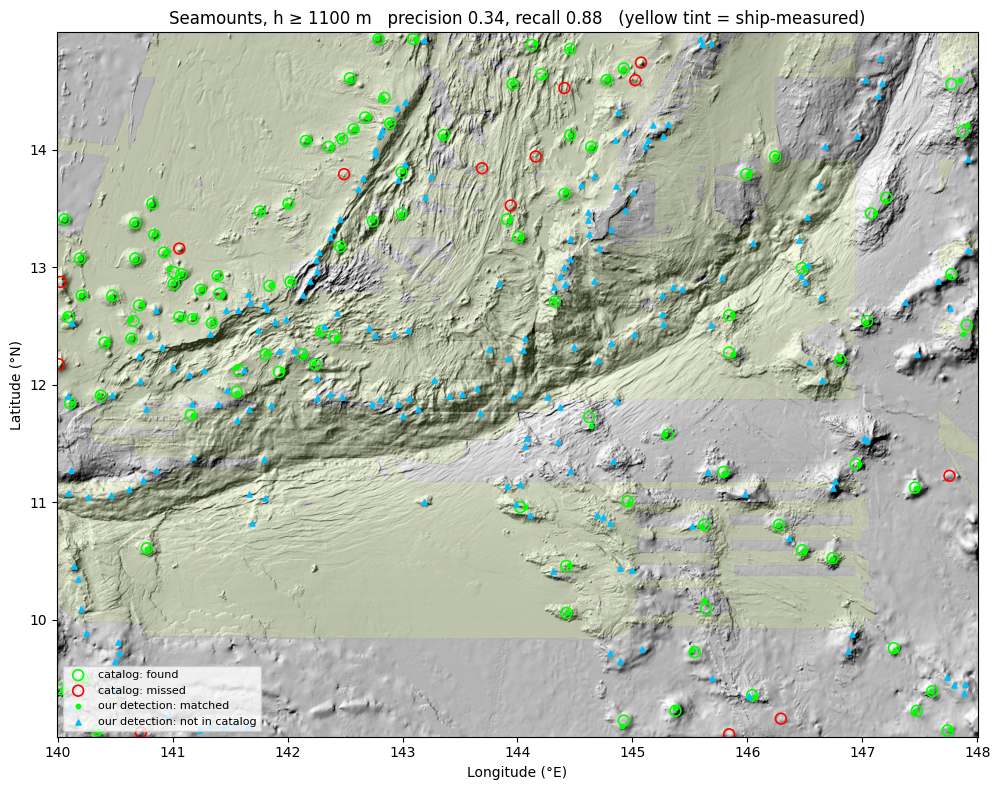

In [6]:
d, dm, cm, pairs, P, R = score(best)
print(f"h_min = {best} m:  {len(dm)} detections, {dm.sum()} matched  →  precision {P:.2f}")
print(f"                  {len(cm)} catalog seamounts, {cm.sum()} found  →  recall {R:.2f}")

fig, ax = plt.subplots(figsize=(11, 8))
ax.imshow(shade, extent=extent, origin="lower", cmap="gray", aspect=aspect)
ax.imshow(np.where(ship, 1, np.nan), extent=extent, origin="lower", cmap="Wistia", alpha=0.18, aspect=aspect)
ax.scatter(c_lon[cm], c_lat[cm], s=60, facecolors="none", edgecolors="lime", lw=1.2, label="catalog: found")
ax.scatter(c_lon[~cm], c_lat[~cm], s=60, facecolors="none", edgecolors="red", lw=1.2, label="catalog: missed")
ax.scatter(d["lon"][dm], d["lat"][dm], s=10, c="lime", label="our detection: matched")
ax.scatter(d["lon"][~dm], d["lat"][~dm], s=14, c="deepskyblue", marker="^", label="our detection: not in catalog")
ax.set(xlabel="Longitude (°E)", ylabel="Latitude (°N)",
       title=f"Seamounts, h ≥ {best} m   precision {P:.2f}, recall {R:.2f}   (yellow tint = ship-measured)")
ax.legend(loc="lower left", fontsize=8)
fig.tight_layout(); fig.savefig(sf.FIG_DIR / "04_seamount_map.png", dpi=200); plt.show()

Recall in ship-measured area:  0.87  (n = 78)
Recall in satellite-only area: 0.90  (n = 40)
Recall for catalog 'charted' seamounts:   0.89  (n = 108)
Recall for catalog 'uncharted' seamounts: 0.80  (n = 10)

  height (m)   ship /10k km²  satellite /10k km²   ratio
  100–300               1.93                4.47    0.43
  300–500               1.87                2.86    0.65
  500–1000              4.00                3.34    1.20
 1000–2000              4.78                3.90    1.22
 2000–10000             1.64                1.04    1.58


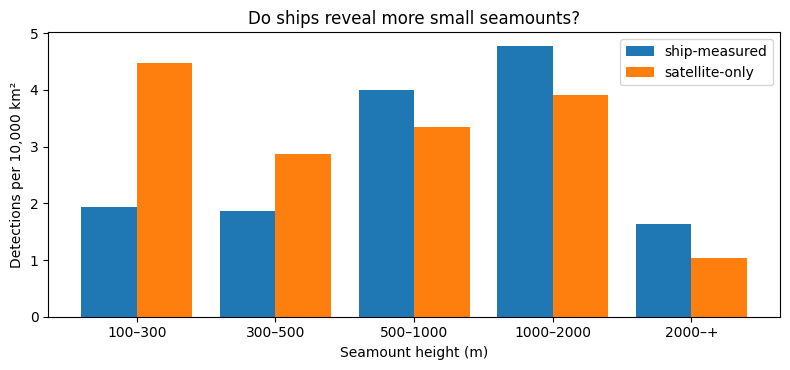

In [7]:
ship_area = (np.cos(np.deg2rad(lat))[:, None] * ship).sum() / np.cos(np.deg2rad(lat))[:, None].repeat(len(lon), 1).sum() * AREA_KM2
sat_area = AREA_KM2 - ship_area

print(f"Recall in ship-measured area:  {cm[c_ship].mean():.2f}  (n = {c_ship.sum()})")
print(f"Recall in satellite-only area: {cm[~c_ship].mean():.2f}  (n = {(~c_ship).sum()})")
print(f"Recall for catalog 'charted' seamounts:   {cm[c_charted].mean():.2f}  (n = {c_charted.sum()})")
print(f"Recall for catalog 'uncharted' seamounts: {cm[~c_charted].mean():.2f}  (n = {(~c_charted).sum()})\n")

bins = [(100, 300), (300, 500), (500, 1000), (1000, 2000), (2000, 10000)]
dens = []
print(f"{'height (m)':>12s} {'ship /10k km²':>15s} {'satellite /10k km²':>19s} {'ratio':>7s}")
for lo_, hi_ in bins:
    m = (det_all["h"] >= lo_) & (det_all["h"] < hi_)
    a = (m & det_all["ship"]).sum() / ship_area * 1e4
    b = (m & ~det_all["ship"]).sum() / sat_area * 1e4
    dens.append((a, b)); print(f"{lo_:>5}–{hi_:<6} {a:15.2f} {b:19.2f} {a / b if b else np.nan:7.2f}")

dens = np.array(dens); x = np.arange(len(bins))
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.bar(x - 0.2, dens[:, 0], 0.4, label="ship-measured"); ax.bar(x + 0.2, dens[:, 1], 0.4, label="satellite-only")
ax.set_xticks(x, [f"{a}–{b if b < 10000 else '+'}" for a, b in bins])
ax.set(xlabel="Seamount height (m)", ylabel="Detections per 10,000 km²", title="Do ships reveal more small seamounts?")
ax.legend(); fig.tight_layout(); fig.savefig(sf.FIG_DIR / "04_ship_vs_satellite.png", dpi=200); plt.show()

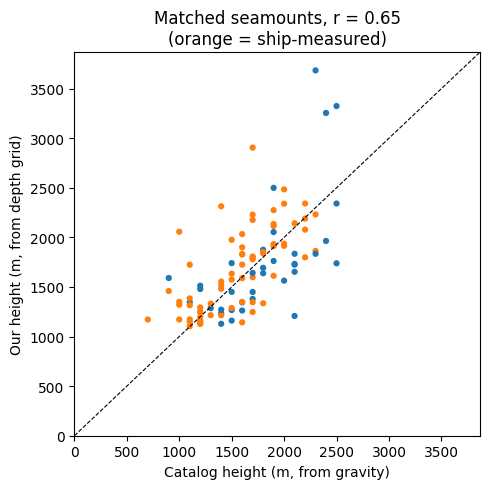

Correlation r = 0.65;  median ratio ours/catalog = 1.02


In [8]:
if len(pairs):
    ours, theirs = d["h"][pairs[:, 0]], c_h[pairs[:, 1]]
    r = np.corrcoef(ours, theirs)[0, 1]
    fig, ax = plt.subplots(figsize=(5, 5))
    ax.scatter(theirs, ours, s=12, c=np.where(d["ship"][pairs[:, 0]], "tab:orange", "tab:blue"))
    lim = [0, max(ours.max(), theirs.max()) * 1.05]; ax.plot(lim, lim, "k--", lw=0.8)
    ax.set(xlim=lim, ylim=lim, xlabel="Catalog height (m, from gravity)", ylabel="Our height (m, from depth grid)",
           title=f"Matched seamounts, r = {r:.2f}\n(orange = ship-measured)")
    fig.tight_layout(); fig.savefig(sf.FIG_DIR / "04_heights.png", dpi=200); plt.show()
    print(f"Correlation r = {r:.2f};  median ratio ours/catalog = {np.median(ours / theirs):.2f}")

In [9]:
print("KEY NUMBERS")
print(f"  Kim & Wessel picks in region: {len(kw)}")
print(f"  Catalog seamounts in region: {len(c_lat)}  (ship area {c_ship.sum()}, satellite-only {(~c_ship).sum()})")
print(f"  Best h_min {best} m: precision {P:.2f}, recall {R:.2f}, F1 {np.nanmax(F1):.2f}")
print(f"  Recall ship vs satellite-only: {cm[c_ship].mean():.2f} vs {cm[~c_ship].mean():.2f}")
for (lo_, hi_), (a, b) in zip(bins, dens):
    print(f"  {lo_}–{hi_} m seamounts per 10k km²: ship {a:.2f} vs satellite {b:.2f}")
if len(pairs): print(f"  Height agreement with catalog: r = {r:.2f}")

KEY NUMBERS
  Kim & Wessel picks in region: 88
  Catalog seamounts in region: 118  (ship area 78, satellite-only 40)
  Best h_min 1100 m: precision 0.34, recall 0.88, F1 0.49
  Recall ship vs satellite-only: 0.87 vs 0.90
  100–300 m seamounts per 10k km²: ship 1.93 vs satellite 4.47
  300–500 m seamounts per 10k km²: ship 1.87 vs satellite 2.86
  500–1000 m seamounts per 10k km²: ship 4.00 vs satellite 3.34
  1000–2000 m seamounts per 10k km²: ship 4.78 vs satellite 3.90
  2000–10000 m seamounts per 10k km²: ship 1.64 vs satellite 1.04
  Height agreement with catalog: r = 0.65
